# Chapitre 5 - Cours 4 : réplication sans leader et quorums

Leader unique ou multi-leader, un leader décide de l'ordre des écritures et les suiveurs
l'appliquent. Certains systèmes abandonnent purement et simplement la notion de leader :
n'importe quelle réplique accepte les écritures des clients. Ce style, présent dans les
tout premiers systèmes répliqués, est redevenu à la mode avec Dynamo, le système interne
d'Amazon (2007), dont s'inspirent Riak, Cassandra et Voldemort (d'où le nom de bases « à la
Dynamo »). Ce cours couvre la section *Leaderless Replication* jusqu'à la détection des
écritures concurrentes, traitée au cours 5.

**Plan.**

1. Écrire quand un nœud est en panne.
2. Rattraper les écritures manquées : lecture réparatrice et anti-entropie.
3. Les quorums : w + r > n.
4. Les limites des quorums, et mesurer la péremption.
5. Quorums approximatifs et transfert différé.
6. Le fonctionnement multi-centres de données.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Écrire quand un nœud est en panne (section *Writing to the Database When a Node Is Down*)

Trois répliques, l'une en cours de redémarrage. Avec un leader, il faudrait peut-être
basculer. Sans leader, il n'y a **pas de basculement** : le client (ou un nœud
coordinateur agissant pour lui) envoie l'écriture aux trois répliques **en parallèle** et
la considère réussie dès que **deux** ont répondu. La troisième rate l'écriture ; quand
elle revient, elle sert des valeurs **périmées**. D'où la règle symétrique : on **lit**
aussi sur plusieurs répliques en parallèle, et on garde la valeur au plus grand numéro de
version.

Le module implémente ce fonctionnement sur le simulateur : `rp.DynamoReplica` stocke
`clé -> (version, valeur)`, `rp.DynamoClient` écrit avec `w` acquittements et lit avec
`r` réponses (ici n = 3, w = 2, r = 2). La réplique `r3` est en panne pendant
l'écriture de la version 7 ; elle redémarre, puis un autre utilisateur lit.

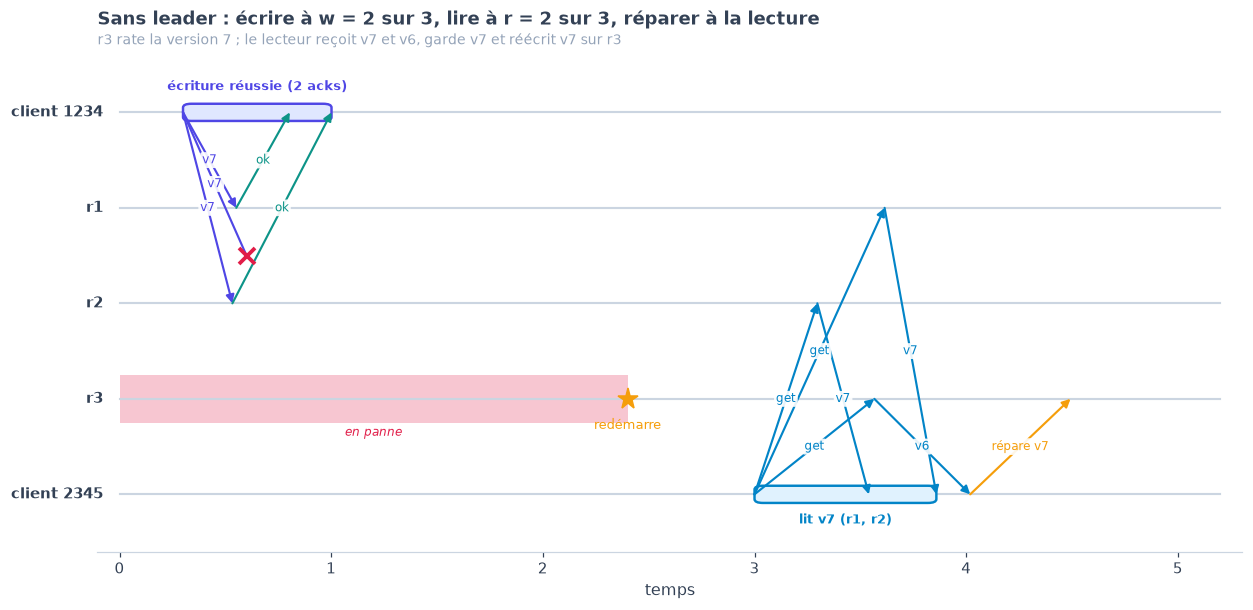

,r1,r2,r3
"(version, valeur) finale","(7, nouvelle)","(7, nouvelle)","(7, nouvelle)"


In [2]:
net, reps, cl = rp.dynamo_cluster(3, 2, 2, latency=(0.2, 0.7), read_repair=True, seed=4,
                                  clients=("client 1234", "client 2345"))
for r_ in reps.values():
    r_.store["photo"] = (6, "ancienne")
net.at(0.0, net.crash, "r3")
net.at(0.3, cl["client 1234"].put, "photo", 7, "nouvelle")
net.at(2.4, net.recover, "r3")
net.at(3.0, cl["client 2345"].get, "photo")
net.run()
colors = {"put": INDIGO, "put_ok": TEAL, "get": SKY, "get_ok": SKY, "repair": AMBER}
def lab(x):
    m = x.msg
    if m[0] == "get_ok":
        return f"v{m[3]}"
    return {"put": "v7", "put_ok": "ok", "get": "get", "repair": "répare v7"}[m[0]]
st = SpaceTime(["client 1234", "r1", "r2", "r3", "client 2345"], t_max=5.2, width=11.5,
               title="Sans leader : écrire à w = 2 sur 3, lire à r = 2 sur 3, réparer à la lecture",
               subtitle="r3 rate la version 7 ; le lecteur reçoit v7 et v6, garde v7 et réécrit v7 sur r3")
st.from_trace(net.trace, color_of=lambda x: colors[x.msg[0]], label_of=lab)
st.span("r3", 0.0, 2.4, "en panne", color=ROSE)
st.event("r3", 2.4, "redémarre", kind="star")
put = [x for x in cl["client 1234"].results if x["type"] == "put"][0]
get = [x for x in cl["client 2345"].results if x["type"] == "get"][0]
st.op("client 1234", put["t0"], put["t1"], "écriture réussie (2 acks)", color=INDIGO)
st.op("client 2345", get["t0"], get["t1"], f"lit v{get['version']} ({', '.join(get['from'])})", color=SKY, above=False)
st.show()
pd.DataFrame({k: [v.store["photo"]] for k, v in reps.items()}, index=["(version, valeur) finale"])

L'écriture réussit avec les acquittements de `r1` et `r2` ; le client ignore simplement que
`r3` l'a ratée. Le lecteur interroge les trois répliques, prend les deux premières réponses,
et garde la version la plus grande, même si elle ne vient que d'une seule réplique. Puis il
remarque qu'une réplique a répondu une version plus ancienne et lui réécrit la bonne : à
la fin, les trois répliques ont la version 7.

> **À retenir.** Sans leader, pas de basculement : on écrit et on lit sur plusieurs
> répliques en parallèle, et les numéros de version désignent la valeur la plus récente.

## 2. Rattraper les écritures manquées (section *Read repair and anti-entropy*)

Une réplique revenue doit finir par recevoir tout ce qu'elle a manqué. Les bases à la
Dynamo combinent plusieurs mécanismes :

- la **lecture réparatrice** (read repair), vue ci-dessus : efficace pour les valeurs
  **souvent lues** ;
- l'**anti-entropie** : un processus de fond compare les répliques et recopie ce qui
  manque, sans ordre particulier et avec un délai parfois important.

**Pourquoi la lecture réparatrice ne suffit pas.** Les accès sont très inégaux : quelques
clés sont lues sans cesse, la plupart rarement. Simulons 100 000 clés, dont 20 % ont été
modifiées pendant l'absence de `r3`, et des lectures distribuées selon une loi de Zipf ;
chaque lecture répare la clé lue. Comparons avec une anti-entropie qui passe toutes les
6 heures.

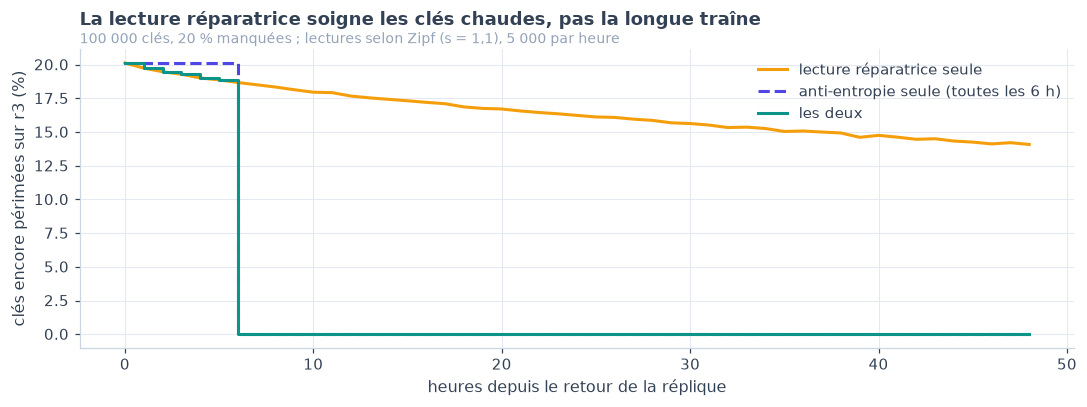

après 48 h de lecture réparatrice seule : 14.1 % des clés encore périmées


In [3]:
K = 100000
stale0 = rng.random(K) < 0.20
poids = 1 / np.arange(1, K + 1) ** 1.1
poids /= poids.sum()
lectures_par_h = 5000
heures = np.arange(0, 49)
rr = []
for h in heures:
    n_lu = rng.binomial(lectures_par_h * h, poids) if h else np.zeros(K, int)
    rr.append(100 * np.mean(stale0 & (n_lu == 0)))
ae = [100 * stale0.mean() if h < 6 else 0 for h in heures]
both = [x if h < 6 else 0 for x, h in zip(rr, heures)]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(heures, rr, color=AMBER, label="lecture réparatrice seule")
ax.step(heures, ae, where="post", color=INDIGO, ls="--", label="anti-entropie seule (toutes les 6 h)")
ax.step(heures, both, where="post", color=TEAL, label="les deux")
ax.set_xlabel("heures depuis le retour de la réplique"); ax.set_ylabel("clés encore périmées sur r3 (%)")
ax.set_title("La lecture réparatrice soigne les clés chaudes, pas la longue traîne")
subtitle(ax, "100 000 clés, 20 % manquées ; lectures selon Zipf (s = 1,1), 5 000 par heure")
ax.legend()
plt.tight_layout(); plt.show()
print(f"après 48 h de lecture réparatrice seule : {rr[-1]:.1f} % des clés encore périmées")

La lecture réparatrice fait chuter vite la part des clés périmées (les clés populaires
sont relues dans l'heure), puis plafonne : les clés de la longue traîne ne sont presque
jamais lues, donc jamais réparées. Seule l'anti-entropie garantit la convergence de
**toutes** les clés, et sans elle une valeur rarement lue peut rester périmée
indéfiniment, au risque d'être perdue si les répliques à jour tombent.

**Comparer deux répliques efficacement : l'arbre de Merkle.** Comparer clé par clé deux
répliques de millions de clés coûterait un transfert énorme. Dynamo utilise un **arbre de
Merkle** : les clés sont réparties en seaux, chaque feuille est le hachage d'un seau,
chaque nœud interne le hachage de ses enfants. Deux répliques comparent leurs racines ;
si elles diffèrent, elles descendent **seulement** dans les sous-arbres différents
(fonctions `rp.merkle_tree` et `rp.merkle_diff`).

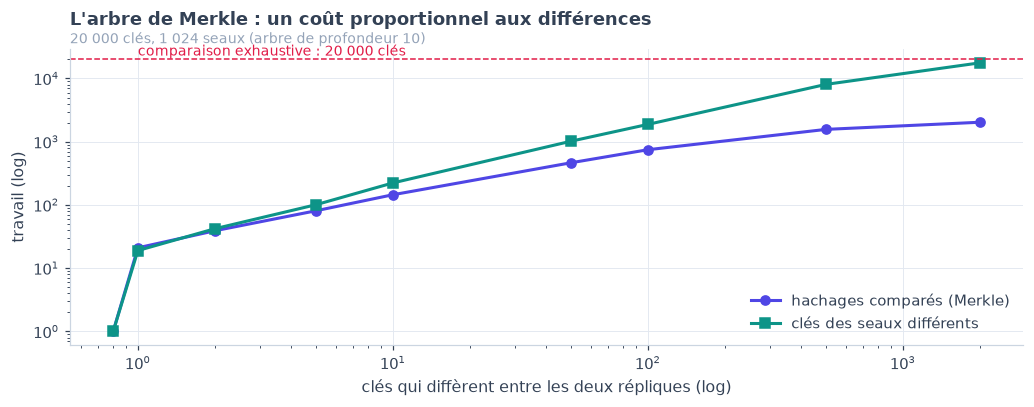

,clés différentes,seaux à resynchroniser,hachages comparés,clés à transférer
0,0,0,1,0
1,1,1,21,19
2,2,2,39,42
3,5,5,81,101
4,10,10,145,223
5,50,50,465,1019
6,100,96,747,1879
7,500,405,1567,8072
8,2000,888,2031,17647


In [4]:
base = {f"k{i}": i for i in range(20000)}
t_a = rp.merkle_tree(base, 1024)
rows = []
for d_ in [0, 1, 2, 5, 10, 50, 100, 500, 2000]:
    other = dict(base)
    for k in rng.choice(20000, d_, replace=False):
        other[f"k{k}"] = -1
    diff, compared = rp.merkle_diff(t_a, rp.merkle_tree(other, 1024))
    rows.append({"clés différentes": d_, "seaux à resynchroniser": len(diff), "hachages comparés": compared,
                 "clés à transférer": sum(1 for k in base if int(rp._h(k), 16) % 1024 in set(diff))})
M = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.loglog(M["clés différentes"].clip(lower=0.8), M["hachages comparés"], "o-", color=INDIGO, label="hachages comparés (Merkle)")
ax.loglog(M["clés différentes"].clip(lower=0.8), M["clés à transférer"].clip(lower=1), "s-", color=TEAL, label="clés des seaux différents")
ax.axhline(20000, color=ROSE, ls="--", lw=1); ax.text(1, 23000, "comparaison exhaustive : 20 000 clés", color=ROSE, fontsize=9)
ax.set_xlabel("clés qui diffèrent entre les deux répliques (log)"); ax.set_ylabel("travail (log)")
ax.set_title("L'arbre de Merkle : un coût proportionnel aux différences")
subtitle(ax, "20 000 clés, 1 024 seaux (arbre de profondeur 10)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
M

Deux répliques identiques se comparent en **un** hachage (la racine). Avec quelques
différences, une vingtaine de hachages par clé différente suffisent (deux par niveau sur
dix niveaux), plus le transfert des seaux concernés. Le coût ne rejoint celui de la
comparaison exhaustive que lorsqu'une grosse fraction des seaux diffère.

> **À retenir.** La lecture réparatrice répare vite les clés lues souvent ; l'anti-entropie
> (par arbres de Merkle) garantit que toutes les clés convergent, pour un coût
> proportionnel au nombre de différences.